# Phase III: Explainable Boosting Machine

This notebook trains an InterpretML Explainable Boosting Classifier (EBM) to predict payment difficulty. It follows the shared preprocessing and validation workflow used by the decision-tree and logistic-regression notebooks. The model is configured with `interactions=0` to keep the explanation additive.

In [ ]:
# Dependencies can be installed with the following command (uncomment to run):
# %pip install -r requirements.txt

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from interpret import show
from interpret.data import ClassHistogram
from interpret.glassbox import ExplainableBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold

from common import (
    CATEGORICAL_COLUMNS,
    DATA_DICTIONARY,
    create_submission,
    encode_features,
    load_data,
    save_predictions,
    split_data,
)

train_data, test_data = load_data()

In [3]:
print("Null values:")
print(train_data.isnull().sum())

print("\nData types:")
print(train_data.dtypes)

print("\nDescriptive statistics:")
display(train_data.describe().T)

target_column = next(
    column
    for column, role in DATA_DICTIONARY.items()
    if role == "target"
)
print("\nTarget counts:")
print(train_data[target_column].value_counts().sort_index())

Null values:
row_id                           0
credit_limit                     0
sex                              0
education                        0
marital_status                   0
age                              0
latest_repayment_status          0
maximum_repayment_delay_6m       0
delayed_months_6m                0
average_bill_6m                  0
bill_change_sep_to_apr           0
total_payment_6m                 0
payment_to_bill_ratio_6m         0
zero_payment_months_6m           0
utilization_sep                  0
repayment_assistance_plan        0
payment_difficulty_next_month    0
dtype: int64

Data types:
row_id                               str
credit_limit                       int64
sex                                  str
education                            str
marital_status                       str
age                                int64
latest_repayment_status            int64
maximum_repayment_delay_6m         int64
delayed_months_6m                  int

,count,mean,std,min,25%,50%,75%,max
credit_limit,25000.0,167740.947200,129975.980819,10000.0,50000.00,140000.00,240000.00,1000000.0
age,25000.0,35.500840,9.243907,21.0,28.00,34.00,41.00,79.0
latest_repayment_status,25000.0,-0.018080,1.120519,-2.0,-1.00,0.00,0.00,8.0
maximum_repayment_delay_6m,25000.0,0.680880,1.070985,0.0,0.00,0.00,2.00,8.0
delayed_months_6m,25000.0,0.833120,1.552059,0.0,0.00,0.00,1.00,6.0
average_bill_6m,25000.0,44910.436000,63267.261940,-56000.0,4700.00,21000.00,57100.00,877300.0
bill_change_sep_to_apr,25000.0,12389.508000,44068.853510,-403600.0,-3000.00,900.00,19900.00,708300.0
total_payment_6m,25000.0,31635.048000,57337.817230,0.0,6700.00,14400.00,33700.00,2314200.0
payment_to_bill_ratio_6m,25000.0,0.374324,0.591434,0.0,0.04,0.09,0.60,5.0
zero_payment_months_6m,25000.0,1.233520,1.722065,0.0,0.00,0.00,2.00,6.0



Target counts:
payment_difficulty_next_month
0    19697
1     5303
Name: count, dtype: int64


In [4]:
data_dictionary = DATA_DICTIONARY
categorical_columns = list(CATEGORICAL_COLUMNS)
split = split_data(train_data, test_data, data_dictionary)

predictor_columns = split.predictor_columns
target_column = split.target_column
X = split.X
y = split.y
X_train = split.X_train
X_validation = split.X_validation
y_train = split.y_train
y_validation = split.y_validation
X_test = split.X_test

In [5]:
encoded = encode_features(split, categorical_columns)
encoder = encoded.encoder
numerical_columns = encoded.numerical_columns
X_train_encoded = encoded.X_train
X_validation_encoded = encoded.X_validation
X_test_encoded = encoded.X_test

X_train_encoded.head()

,credit_limit,age,latest_repayment_status,maximum_repayment_delay_6m,delayed_months_6m,average_bill_6m,bill_change_sep_to_apr,total_payment_6m,payment_to_bill_ratio_6m,zero_payment_months_6m,...,education_graduate_school,education_high_school,education_other,education_university,education_unknown,marital_status_married,marital_status_other_or_unknown,marital_status_single,repayment_assistance_plan_no,repayment_assistance_plan_yes
21143,60000,34,2,2,1,59000,-800,13500,0.04,0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
9555,80000,65,0,0,0,51600,77100,9600,0.03,0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
16143,160000,26,-1,0,0,11300,-8100,72400,1.07,0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
22939,20000,23,0,2,1,16400,-500,8000,0.08,1,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
11685,340000,62,0,0,0,495100,37800,116400,0.04,0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=411)
cv_scores = {
    "accuracy": [],
    "balanced_accuracy": [],
    "recall_class_0": [],
    "recall_class_1": [],
}

for train_indices, validation_indices in cv.split(X_train_encoded, y_train):
    fold_ebm = ExplainableBoostingClassifier(
        interactions=0,
        outer_bags=4,
        max_rounds=5000,
        early_stopping_rounds=50,
        n_jobs=1,
        random_state=411,
    )
    fold_ebm.fit(
        X_train_encoded.iloc[train_indices],
        y_train.iloc[train_indices],
    )
    fold_predictions = fold_ebm.predict(
        X_train_encoded.iloc[validation_indices]
    )
    fold_targets = y_train.iloc[validation_indices]
    cv_scores["accuracy"].append(
        accuracy_score(fold_targets, fold_predictions)
    )
    cv_scores["balanced_accuracy"].append(
        balanced_accuracy_score(fold_targets, fold_predictions)
    )
    cv_scores["recall_class_0"].append(
        recall_score(fold_targets, fold_predictions, pos_label=0)
    )
    cv_scores["recall_class_1"].append(
        recall_score(fold_targets, fold_predictions, pos_label=1)
    )

for metric_name, scores in cv_scores.items():
    print(
        f"Five-fold {metric_name}: "
        f"{np.mean(scores):.3f} +/- {np.std(scores):.3f}"
    )

Five-fold accuracy: 0.817 +/- 0.003
Five-fold balanced_accuracy: 0.625 +/- 0.008
Five-fold recall_class_0: 0.958 +/- 0.004
Five-fold recall_class_1: 0.292 +/- 0.018


In [7]:
histogram = ClassHistogram().explain_data(
    X_train,
    y_train,
    name="Training data",
)
show(histogram)

<!-- http://127.0.0.1:7291/2492341512112/ -->

In [8]:
ebm_baseline = ExplainableBoostingClassifier(
    interactions=0,
    outer_bags=4,
    max_rounds=5000,
    early_stopping_rounds=50,
    n_jobs=1,
    random_state=411,
)
ebm_baseline.fit(X_train_encoded, y_train)
baseline_predictions = ebm_baseline.predict(X_validation_encoded)

print("Baseline validation accuracy: "
      f"{accuracy_score(y_validation, baseline_predictions):.3f}")
print("Baseline validation balanced accuracy: "
      f"{balanced_accuracy_score(y_validation, baseline_predictions):.3f}")
print(classification_report(y_validation, baseline_predictions))

Baseline validation accuracy: 0.823
Baseline validation balanced accuracy: 0.633
              precision    recall  f1-score   support

           0       0.84      0.96      0.90      5909
           1       0.68      0.30      0.42      1591

    accuracy                           0.82      7500
   macro avg       0.76      0.63      0.66      7500
weighted avg       0.80      0.82      0.79      7500



In [9]:
param_grid = {
    "max_leaves": [2, 3],
    "learning_rate": [0.01, 0.03],
}

grid_search = GridSearchCV(
    estimator=ExplainableBoostingClassifier(
        interactions=0,
        outer_bags=4,
        max_rounds=5000,
        early_stopping_rounds=50,
        n_jobs=1,
        random_state=411,
    ),
    param_grid=param_grid,
    scoring="balanced_accuracy",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=411),
    n_jobs=1,
)
grid_search.fit(X_train_encoded, y_train)
print(f"Best parameters: {grid_search.best_params_}")
print(f"Best CV balanced accuracy: {grid_search.best_score_:.3f}")

Best parameters: {'learning_rate': 0.01, 'max_leaves': 2}
Best CV balanced accuracy: 0.624


In [10]:
ebm = ExplainableBoostingClassifier(
    interactions=0,
    outer_bags=4,
    max_rounds=5000,
    early_stopping_rounds=50,
    n_jobs=1,
    random_state=411,
    **grid_search.best_params_,
)
ebm.fit(X_train_encoded, y_train)

validation_predictions = ebm.predict(X_validation_encoded)
validation_probabilities = ebm.predict_proba(X_validation_encoded)[:, 1]
print(f"Validation accuracy: {accuracy_score(y_validation, validation_predictions):.3f}")
print("Validation balanced accuracy: "
      f"{balanced_accuracy_score(y_validation, validation_predictions):.3f}")
print(classification_report(y_validation, validation_predictions))

Validation accuracy: 0.822
Validation balanced accuracy: 0.631
              precision    recall  f1-score   support

           0       0.84      0.96      0.89      5909
           1       0.68      0.30      0.42      1591

    accuracy                           0.82      7500
   macro avg       0.76      0.63      0.66      7500
weighted avg       0.80      0.82      0.79      7500



<!-- http://127.0.0.1:7291/2492372463840/ -->

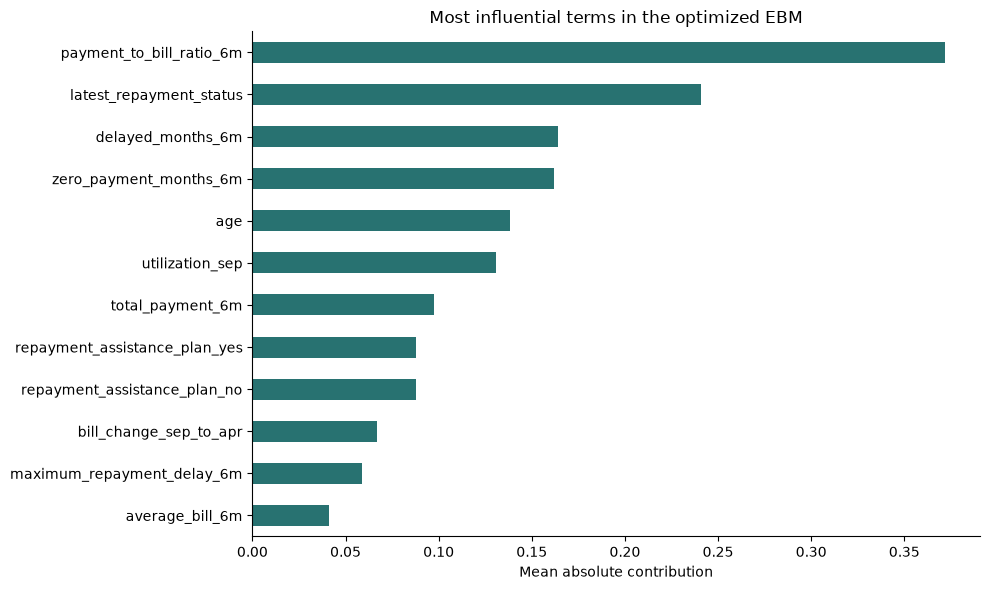

In [11]:
ebm_global = ebm.explain_global(name="Optimized Explainable Boosting Classifier")
show(ebm_global)

term_importances = pd.Series(
    ebm.term_importances(),
    index=ebm.term_names_,
    name="importance",
)
top_importances = term_importances.nlargest(12).sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
top_importances.plot.barh(ax=ax, color="#287271")
ax.set_title("Most influential terms in the optimized EBM")
ax.set_xlabel("Mean absolute contribution")
ax.set_ylabel("")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("../report/figures/ebm_global_importance.png", dpi=240, bbox_inches="tight")
plt.show()

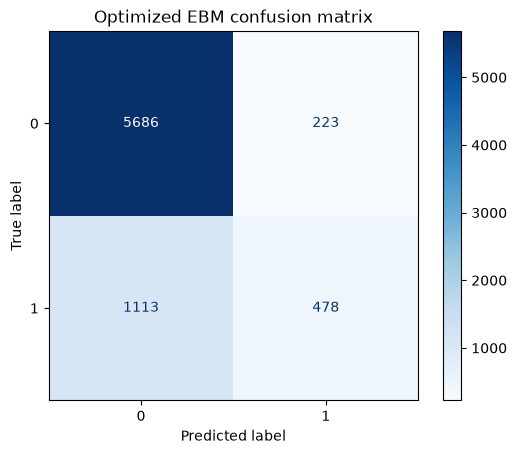

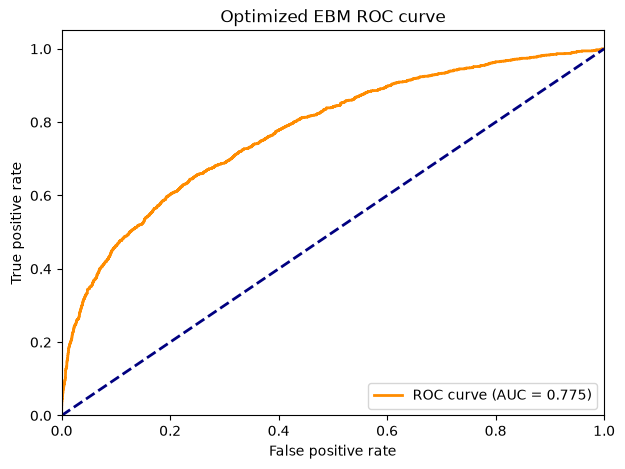

In [12]:
confusion = confusion_matrix(y_validation, validation_predictions)
confusion_display = ConfusionMatrixDisplay(
    confusion_matrix=confusion,
    display_labels=ebm.classes_,
)
confusion_display.plot(cmap=plt.cm.Blues)
plt.title("Optimized EBM confusion matrix")
plt.grid(False)
plt.show()

false_positive_rate, true_positive_rate, _ = roc_curve(
    y_validation,
    validation_probabilities,
)
auc_score = roc_auc_score(y_validation, validation_probabilities)
plt.figure(figsize=(7, 5))
plt.plot(
    false_positive_rate,
    true_positive_rate,
    color="darkorange",
    lw=2,
    label=f"ROC curve (AUC = {auc_score:.3f})",
)
plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Optimized EBM ROC curve")
plt.legend(loc="lower right")
plt.show()

In [13]:
validation_targets = y_validation.to_numpy()
prediction_values = np.asarray(validation_predictions)
candidate_cases = (
    ("Class 0: correctly predicted", np.flatnonzero((validation_targets == 0) & (prediction_values == 0))),
    ("Class 1: correctly detected", np.flatnonzero((validation_targets == 1) & (prediction_values == 1))),
    ("Class 1: missed by the model", np.flatnonzero((validation_targets == 1) & (prediction_values == 0))),
)
local_positions = []
local_labels = []
for case_label, positions in candidate_cases:
    if positions.size:
        local_positions.append(int(positions[0]))
        local_labels.append(case_label)

if not local_positions:
    raise ValueError("No representative validation cases were found.")

local_X = X_validation_encoded.iloc[local_positions]
local_y = y_validation.iloc[local_positions]
ebm_local = ebm.explain_local(local_X, local_y, name="Representative validation cases")
local_summary = pd.DataFrame(
    {
        "case": local_labels,
        "validation_row": X_validation.index[local_positions],
        "actual_class": local_y.to_numpy(),
        "predicted_class": prediction_values[local_positions],
        "predicted_probability": ebm.predict_proba(local_X)[:, 1],
    }
)
show(ebm_local)
with pd.option_context("display.max_colwidth", None):
    display(local_summary)

<!-- http://127.0.0.1:7291/2492436952592/ -->

,case,validation_row,actual_class,predicted_class,predicted_probability
0,Class 0: correctly predicted,22764,0,0,0.048919
1,Class 1: correctly detected,4951,1,1,0.619002
2,Class 1: missed by the model,19211,1,0,0.212360


Predictions saved to C:\Users\thale\Documents\GitHub\explainable-artificial-intelligence\Inteligencia Artificial Explicable\Tema 2 - trabajo práctico\data\explainable_boosting_test_predictions.csv


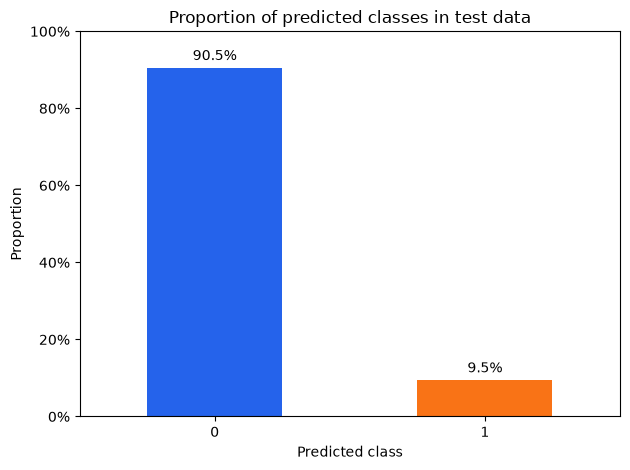

,row_id,credit_limit,sex,education,marital_status,age,latest_repayment_status,maximum_repayment_delay_6m,delayed_months_6m,average_bill_6m,bill_change_sep_to_apr,total_payment_6m,payment_to_bill_ratio_6m,zero_payment_months_6m,utilization_sep,repayment_assistance_plan,predicted_class
0,CR26-128173,50000,male,graduate_school,single,25,0,0,0,27700,31600,21700,0.13,0,0.80,no,0
1,CR26-102911,280000,female,university,married,41,1,1,1,100,300,600,0.63,4,0.00,no,0
2,CR26-104960,420000,male,university,married,38,0,0,0,262500,108200,56200,0.04,0,0.70,no,0
3,CR26-123913,270000,male,university,single,44,0,0,0,247400,48900,56400,0.04,0,1.02,no,0
4,CR26-111750,120000,female,graduate_school,single,29,-1,0,0,1700,-2100,12000,1.20,0,0.00,yes,0


In [14]:
model_name = "explainable_boosting"
test_predictions = ebm.predict(X_test_encoded)
submission = create_submission(test_data, test_predictions)
output_path = save_predictions(submission, model_name)
print(f"Predictions saved to {output_path}")

class_proportions = (
    submission["predicted_class"]
    .value_counts(normalize=True)
    .sort_index()
)
ax = class_proportions.plot(
    kind="bar",
    color=["#2563eb", "#f97316"],
    title="Proportion of predicted classes in test data",
    ylabel="Proportion",
    xlabel="Predicted class",
    ylim=(0, 1),
)
ax.set_xticklabels(class_proportions.index, rotation=0)
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f"{value:.0%}")
)
for index, proportion in enumerate(class_proportions):
    ax.text(index, proportion + 0.02, f"{proportion:.1%}", ha="center")
plt.tight_layout()
plt.show()

submission.head()